# Dataset Understanding and Policy Baseline

## Problem Statement

**Priya** is an ASHA (Accredited Social Health Activist) worker in rural India managing
847 patients across 3 villages. Every morning she sees patients and must decide quickly:
*Can this wait? Does this need a doctor today? Should this person go to the ER right now?*

We have a dataset of 853 patient cases covering 22 diagnosis types, written as
natural-language symptom descriptions -- exactly the messy free-text Priya receives.
Your job is to understand that data and build a **deterministic policy baseline**
that makes the WAIT / DOCTOR / ER call using hand-written Python rules, no LLM needed.

## What You Are Building

You will implement **three functions** in `sahayak_starter.py`:

| Function | What it does | Where in this notebook |
|---|---|---|
| `score_severity()` | Score urgency 1-5 using keyword rules | Cell 17 will crash until done |
| `decide_triage()` | Map the score to WAIT / DOCTOR / ER | Called by run_policy_triage |
| `run_policy_triage()` | Wire the full pipeline end-to-end | Cell 17 |

Everything else is **given** -- you run it, read it, and build on top of it.

## Learning Objectives

By the end of this notebook you will be able to:

1. Explain why **pain intensity is not urgency** (migraine = painful but WAIT)
2. Describe the **asymmetric loss** between under-triage and over-triage
3. Read a confusion matrix and name which triage class your baseline fails on
4. Explain what a **seed-locked evaluation set** is and why it must never change
5. Articulate the limit of a rule-based system vs. an LLM agent

## Terminal Objectives (your deliverables)

- [ ] `sahayak_starter.py` -- `score_severity`, `decide_triage`, `run_policy_triage` implemented
- [ ] 50-case evaluation run with metrics printed (cell 18)
- [ ] Trace table built showing correct vs. incorrect predictions (cell 19)
- [ ] System design note filled in (cell 23)

---

> **Working rhythm**: Run cells top to bottom. When a cell raises `NotImplementedError`,
> open `sahayak_starter.py`, implement the named function, save, and re-run the cell.
> The docstrings in `sahayak_starter.py` tell you exactly what to build and in what order.

---


<!-- ASSESSMENT_GUIDE v1 -->
## Assessment & Submission Guide  ·  21 marks

**Learning objectives — by the end of this notebook you can:**
- Load and profile the dataset (text length, 22-label distribution).
- Review and justify the provided diagnosis->triage mapping (given as TRIAGE_MAP).
- Create a fixed stratified evaluation sample and state train/test discipline.
- Evaluate a transparent policy baseline and explain why it fails on natural language.
- Build the symptom parser and severity scorer as `LlmAgent`s with a trace table.

**Files to modify & submit:**
- `data_understanding_and_baseline.ipynb` — complete and execute all cells.
- `sahayak_starter.py` — implement `score_severity()`, `decide_triage()`, `run_policy_triage()`.

**Files provided for reference (do not submit):**
- `data_loader.py`
- `utils.py`

**Depends on:** `adk_foundations.ipynb`

**Stage → Task → Sub-task → Marks → Expected output**

| Task | Marks | Sub-task | Marks | Expected output | 
|---|---:|---|---:|---|
| **1.3 Exploratory Data Analysis** | **4** | 1.3.1 | 4 | `.head()`, text-length stats, and the 22-label distribution plot | 
| **1.4 Construct Ground Truth & Evaluation Sample** | **7** | 1.4.1 | 4 | Review pre-built TRIAGE_MAP; spot-check; justify >=3 ambiguous label decisions in writing |
|  |  | 1.4.2 | 3 | Fixed stratified n=50 sample (fixed seed) + split-discipline statement | 
| **2.1 Transparent Policy Baseline** | **6** | 2.1.1 | 4 | Baseline accuracy and per-class (WAIT/DOCTOR/ER) recall on the fixed sample | baseline results table |
|  |  | 2.1.2 | 2 | Dominant failure mode + >=2 concrete misclassified examples | 
| **2.2 First Two ADK Stages (Parser + Severity)** | **4** | 2.2.1 | 4 | Build the symptom parser + severity scorer as LlmAgents with a >=10-row trace table | 
| | | | **21** ||

**What counts as a completed deliverable:**
- The notebook executes top-to-bottom in Colab (Gemini) or locally (Ollama) with no errors.
- Every claimed number is visible as a notebook cell output (no separate .json artifacts required).
- Every sub-task above has visible evidence in the listed location.
- Attach `final_report.pdf` covering methodology, eval results, failure analysis, known limits, and dashboard screenshots.

> **Priya's situation**: She has seen 847 patients across 3 villages this year.
> We have 853 patient cases in a public
> dataset covering 22 conditions she encounters -- written as first-person,
> natural-language symptom descriptions, exactly the messy input she relays.
> In this notebook, you will understand that data before you build anything.
> A system Priya can trust starts with an analyst who understood the population.


## Concept Coverage

**Prerequisite from previous notebook**: `LlmAgent`, `SequentialAgent`, `output_key`, `Runner`, `session.state`.

**New concepts in this notebook** (scaffolded -- structure given, you fill in specifics):

| Concept | What it is | Where |
|---|---|---|
| Dataset + triage mapping | 853 labeled cases, 22 diagnosis labels -> 3 classes | Day 1-2 |
| Fixed evaluation sample | Lock `n=50, seed=42` now; never retune on it | Day 3-4 |
| Policy baseline | Deterministic rule engine; the number to beat in the next notebook `agent_pipeline_development.ipynb` | Day 3-4 |
| Trace table | `predicted_triage` vs `true_triage`; under-triage = safety failure | Day 3-4 |
| `FunctionTool` interface | 4 tools the agent will call; RAG/drug/vitals/NEWS2 | Day 4 |
| System design note | Written artifact: target user, data, tools, risk, metrics | Day 5 |

**You already know RAG** -- the `search_symptom_cases_db` tool uses it.
The exhibit shows what the hybrid (Jaccard + cosine) call returns so you know the interface
before you wire it as a `FunctionTool` in the next notebook `agent_pipeline_development.ipynb`.


In [1]:
# >>> output-hygiene (HF/torch import advisories are not errors) >>>
import os as _os, logging as _logging, warnings as _warnings
for _k, _v in {"HF_HUB_DISABLE_IMPLICIT_TOKEN": "1", "HF_HUB_DISABLE_PROGRESS_BARS": "1",
               "HF_HUB_DISABLE_TELEMETRY": "1", "HF_HUB_VERBOSITY": "error",
               "TRANSFORMERS_VERBOSITY": "error", "TRANSFORMERS_NO_ADVISORY_WARNINGS": "1",
               "TOKENIZERS_PARALLELISM": "false"}.items():
    _os.environ.setdefault(_k, _v)
_warnings.filterwarnings("ignore")
for _n in ("huggingface_hub", "huggingface_hub.utils._http", "transformers",
           "sentence_transformers", "datasets", "torch",
           "torch.distributed.elastic.multiprocessing.redirects", "torchao"):
    _logging.getLogger(_n).setLevel(_logging.ERROR)
# <<< output-hygiene <<<
# -- COLAB SETUP ---------------------------------------------------------
# !pip install -q 'google-adk>=2.0.0' google-genai datasets pandas matplotlib seaborn scikit-learn
import os
# from google.colab import userdata
# os.environ['GOOGLE_API_KEY'] = userdata.get('GOOGLE_API_KEY')
# os.environ['GOOGLE_GENAI_USE_VERTEXAI'] = 'FALSE'
print('Setup done.')

Setup done.


In [2]:
import sys, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.insert(0, '.')
import warnings; warnings.filterwarnings('ignore')

<!-- TASKMARK -->
## Task 1.3 — Exploratory Data Analysis
### **1.3.1** <font color="red">[4 marks]</font> — Load and profile the dataset

Load the dataset and show`.head()`, text-length statistics, and the 22-label distribution plot.

## Day 1-2: Dataset Exploration

Dataset: `gretelai/symptom_to_diagnosis` -- 853 labeled cases,
22 diagnosis labels, first-person natural-language symptom text.
Your job: understand the data before building the agent.

In [3]:
# -- data_loader.py -- GIVEN, do not modify -----------------------------------
# Public API (everything you need from this file):
#
#   TRIAGE_MAP                   dict: 41 known diagnoses (dataset uses 22) -> WAIT / DOCTOR / ER
#   load_sahayak_dataset()    -> DataFrame (853 HuggingFace train cases)
#   build_evaluation_dataset() -> DataFrame (locked 50-case eval split)
#
# Falls back to a small built-in sample if HuggingFace is offline.
# You do NOT build or modify this file.
from data_loader import load_sahayak_dataset
df = load_sahayak_dataset()
print("Dataset shape:", df.shape)
print(df["triage_level"].value_counts())
df.head(3)


Generating train split:   0%|          | 0/853 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/212 [00:00<?, ? examples/s]

Dataset shape: (853, 3)
triage_level
WAIT      429
DOCTOR    387
ER         37
Name: count, dtype: int64


,symptom_text,diagnosis,triage_level
0,I've been having a lot of pain in my neck and ...,cervical spondylosis,WAIT
1,I have a rash on my face that is getting worse...,impetigo,WAIT
2,I have been urinating blood. I sometimes feel ...,urinary tract infection,DOCTOR


In [4]:
# -- Check for missing values and duplicates ------------------------------
print('Missing values:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())
print('Unique diagnoses:', df['diagnosis'].nunique())

Missing values:
symptom_text    0
diagnosis       0
triage_level    0
dtype: int64

Duplicate rows: 4
Unique diagnoses: 22


---
## Your Work Starts Here

Everything above is setup code, data exploration context, and tool demos — run it and read it.

Cells below marked `# FILL IN`, `# YOUR FILE`, or `# YOUR ...` are your work:

| Cell | What to build |
|---|---|
| Spot-check (below) | Print 5 rows from each triage level |
| `run_policy_triage()` | Your rule-based triage function |
| FunctionTool wrappers | Wrap the 4 sahayak tools as ADK `FunctionTool` objects |
| System design note | One-paragraph write-up of your `data_understanding_and_baseline.ipynb` architecture |


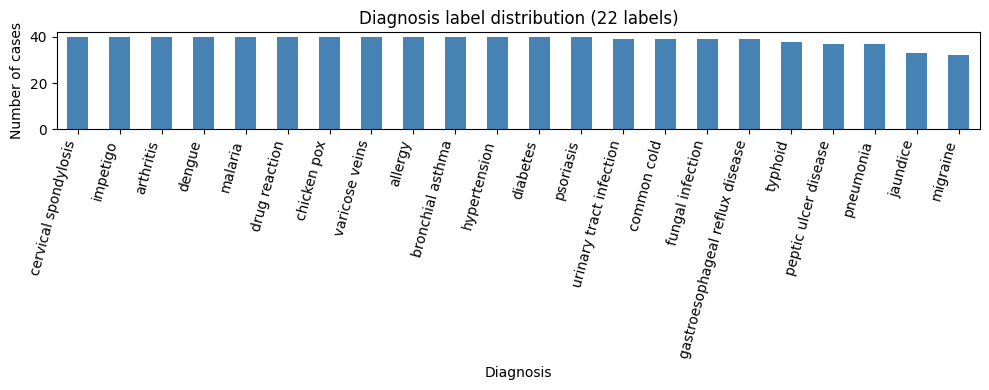

Top 3 diagnoses:
diagnosis
cervical spondylosis    40
impetigo                40
arthritis               40
Name: count, dtype: int64


In [5]:
# -- Distribution of diagnosis labels (Task 1.3.1) -------------------------

counts = df['diagnosis'].value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
counts.plot(kind='bar', ax=ax, color='steelblue')
ax.set_xlabel('Diagnosis')
ax.set_ylabel('Number of cases')
ax.set_title(f'Diagnosis label distribution ({df["diagnosis"].nunique()} labels)')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

print('Top 3 diagnoses:')
print(counts.head(3))
# ER is only ~4% of cases, so plain accuracy can hide a bad ER recall


<!-- TASKMARK -->
## Task 1.4 — Construct Ground Truth and Evaluation Sample
### **1.4.1** Review the diagnosis → triage mapping <font color="red">[4 marks]</font>

Spot-check the given map; write a clinical justification for ≥3 ambiguous calls.

## Day 1-2: Review the Triage Map (your ground truth)

The diagnosis -> WAIT / DOCTOR / ER map is **given** in `data_loader.py` as `TRIAGE_MAP`.
You do **not** build it. Your job is to *understand and sanity-check* it, because every
metric in all the notebooks are measured against this map.

How the three levels are defined:
- **ER**: life-threatening within hours (heart attack, brain hemorrhage, pneumonia)
- **DOCTOR**: needs clinical review, not immediately life-threatening (UTI, diabetes, jaundice)
- **WAIT**: manageable without a doctor visit today (mild cold, fungal infection, mild acne)

**Your graded task (1.4.1):** display the map, spot-check ~5 cases per level (next cells),
then write a one-line clinical justification for **3 ambiguous calls** -- e.g. *why is
jaundice DOCTOR and not ER?* Fill these into the justifications cell below.

In [6]:
# -- TRIAGE_MAP -- GIVEN ------------------------------------------------------
# Maps 41 known diagnosis names to WAIT / DOCTOR / ER (current dataset uses 22).
# ER = immediate emergency  |  DOCTOR = same-day review  |  WAIT = home care
#
# Your score_severity() rules in the cells below must be consistent with this
# map -- read it before you write a single line of scoring logic.
from data_loader import TRIAGE_MAP

# Display as a DataFrame so you can sort and scan it
import pandas as pd
pd.DataFrame(list(TRIAGE_MAP.items()), columns=["diagnosis","triage_level"]).sort_values("triage_level")


,diagnosis,triage_level
20,Hepatitis B,DOCTOR
25,Tuberculosis,DOCTOR
24,Alcoholic hepatitis,DOCTOR
23,Hepatitis E,DOCTOR
22,Hepatitis D,DOCTOR
21,Hepatitis C,DOCTOR
31,Hypothyroidism,DOCTOR
32,Hyperthyroidism,DOCTOR
18,Typhoid,DOCTOR
17,Dengue,DOCTOR


Triage distribution:
triage_level
WAIT      429
DOCTOR    387
ER         37
Name: count, dtype: int64


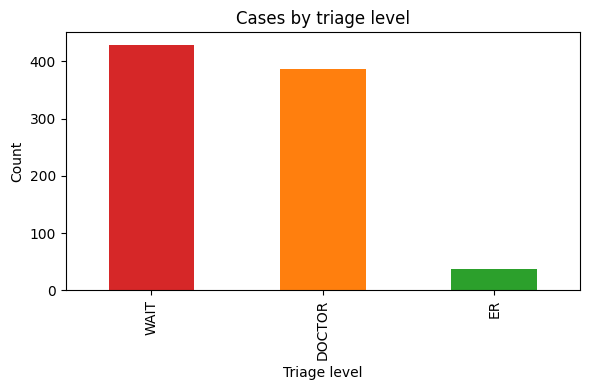

Smallest class: ER


In [7]:
# Triage distribution -- the loader already provides triage_level via the
# case-insensitive canonical TRIAGE_MAP (plus aliases for renamed diseases).
print('Triage distribution:')
print(df['triage_level'].value_counts())

fig, ax = plt.subplots(figsize=(6, 4))
df['triage_level'].value_counts().plot(kind='bar', ax=ax,
    color=['#d62728', '#ff7f0e', '#2ca02c'])
ax.set_title('Cases by triage level')
ax.set_xlabel('Triage level')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

print('Smallest class:', df['triage_level'].value_counts().idxmin())
# ER is the smallest class, so one miss moves its recall a lot
# a lot, and a model that never predicts ER would still score well on plain accuracy.

In [8]:
# -- Spot-check 5 rows from each triage level -----------------------------
# Goal: verify the mapping looks sensible for each class
spot_check = pd.concat([df[df['triage_level'] == lv].sample(min(5, (df['triage_level'] == lv).sum()), random_state=42)
                        for lv in ['ER', 'DOCTOR', 'WAIT']])
print(spot_check['triage_level'].value_counts().to_dict())

for level in ['ER', 'DOCTOR', 'WAIT']:
    sample = df[df['triage_level'] == level].sample(min(5, len(df[df["triage_level"] == level])), random_state=42)
    print(f'\n-- {level} examples --')
    for _, row in sample.iterrows():
        print(f'  [{row["diagnosis"]}] {str(row["symptom_text"])[:80]}...')

# --- YOUR JUSTIFICATIONS (graded 1.4.1) ----------------------------------
# Pick 3 diagnoses whose WAIT/DOCTOR/ER call is debatable and defend each in one line.
# Example -> "Jaundice": "DOCTOR not ER: usually hepatitis/gallstones, time-sensitive but not hours-to-die"
triage_map_justifications = {
    "Jaundice": "DOCTOR not ER: needs liver tests soon, but a stable patient is not at risk within hours",
    "Pneumonia": "ER not DOCTOR: breathing can worsen fast and the patient may need oxygen, which a clinic visit later cannot give",
    "Migraine": "WAIT not DOCTOR: vomiting and light sensitivity sound dramatic, but it is self-limiting; dramatic language is not urgency",
}
for _dx, _why in triage_map_justifications.items():
    print(f"{_dx}: {_why}")

{'ER': 5, 'DOCTOR': 5, 'WAIT': 5}

-- ER examples --
  [pneumonia] I'm feeling really hot. I can't breathe well. I'm sweating a lot. I'm shaking. I...
  [pneumonia] I'm having trouble breathing and I feel really uncomfortable. I'm sweating a lot...
  [pneumonia] I've been feeling really cold and tired lately. I've been coughing a lot, and it...
  [pneumonia] I'm having trouble breathing and I feel really uncomfortable. I'm sweating a lot...
  [pneumonia] I've been feeling really run down lately. I've had a cough that just won't go aw...

-- DOCTOR examples --
  [bronchial asthma] I've been having trouble breathing, coughing a lot, and running a fever. I've al...
  [malaria] I've been having a fever, chills, and nausea. I've also been sweating a lot and ...
  [hypertension] I've been having chest pain, dizziness, and a headache that feels like it's in a...
  [peptic ulcer disease] I have trouble swallowing food and it feels like food is getting stuck in my thr...
  [hypertension] I've b

<!-- TASKMARK -->
### **1.4.2** Create the fixed evaluation sample <font color="red">[3 marks]</font> 

Create a stratified n=50 sample with a fixed seed and state the train/test discipline.

## Day 3-4: Fixed Evaluation Sample

**Lock this now. Do not change it.**

`build_evaluation_dataset(n=50, seed=42)` gives a stratified sample:
proportional representation of WAIT / DOCTOR / ER.

All accuracy numbers in the next notebooks use this same 50 cases.
This prevents you from improving the score by cherry-picking easier cases.

**How the split works (the only data discipline you need):** the dataset has 853
labeled cases. These 50 (seed=42) are your **held-out test set** -- you never tune on
them. The remaining cases are free for calibration in `agent_evaluation_and_optimisation.ipynb`. There is no separate file
to download; this locked sample *is* the capstone's test set.

In [9]:
# -- build_evaluation_dataset() -- GIVEN ---------------------------------------
# Returns exactly 50 cases, stratified across WAIT / DOCTOR / ER.
# Columns: symptom_text, diagnosis, triage_level
#
# LOCK: always use n=50, seed=42. This benchmark never changes.
# All four notebooks measure against this same set so numbers are comparable.
from data_loader import build_evaluation_dataset

eval_df = build_evaluation_dataset(n=50, seed=42)  # LOCK -- do not change seed
print("Evaluation set shape:", eval_df.shape)
print(eval_df["triage_level"].value_counts())
eval_df.head(3)


Evaluation set shape: (50, 3)
triage_level
WAIT      17
DOCTOR    17
ER        16
Name: count, dtype: int64


,symptom_text,diagnosis,triage_level
0,I have been experiencing cramps in my legs for...,varicose veins,WAIT
1,I'm having trouble breathing. I'm coughing up ...,pneumonia,ER
2,I have a burning pain in my stomach that comes...,peptic ulcer disease,DOCTOR


<!-- TASKMARK -->
# Stage 2 — Baseline System <font color="red">[10 marks]</font> 
## Task 2.1 — Transparent Policy Baseline
### **2.1.1** Evaluate the baseline <font color="red">[4 marks]</font>

Implement the keyword/rule baseline and evaluate it on the fixed sample; report accuracy and per-class recall.

## Day 3-4: Policy Baseline

Before building the ADK agent, run the transparent rule-based policy.
This is your **baseline** -- a concrete number to beat in the next notebook `agent_pipeline_development.ipynb`.

The policy does NOT call Gemini. It runs entirely offline.
This proves you can test the triage logic without spending API quota.

### Anatomy of a Policy Trace

Every call to `run_policy_triage(text)` returns a dict with these keys.
Read this before running the baseline -- you will be asked to interpret each field.

| Key | Type | What it contains |
|-----|------|------------------|
| `patient_input` | str | The original text you passed in |
| `symptoms` | list[str] | Extracted visible symptoms, e.g. `['fever', 'duration:3 days']` |
| `clinical_context` | dict | Red flag groups and vulnerability flags detected |
| `severity_json` | dict | `{severity: 1-5, reason: '...'}` -- the urgency score |
| `followup` | dict | `{needed: bool, question: str|null}` -- clarifying question if ambiguous |
| `triage_decision` | dict | `{triage_level: 'WAIT'|'DOCTOR'|'ER', rule_applied: '...'}` |
| `predicted_triage` | str | Just the label -- `'WAIT'`, `'DOCTOR'`, or `'ER'` |
| `final_response` | str | The full Priya-ready response including disclaimer |
| `safety_audit` | dict | `{verdict, risk_level, violations, human_review_needed, stage_to_debug, reason}` |

> **Key insight**: `predicted_triage` == `triage_decision['triage_level']`.
> They are the same value -- one is for convenience, one is for the full audit trail.
> In `agent_evaluation_and_optimisation.ipynb` you will compare `predicted_triage` against `true_triage` for 50 cases.


In [10]:
# -- sahayak_starter.py -- YOUR FILE -------------------------------------------
# run_policy_triage() is one of the THREE functions you will build in this notebook.
# Right now it raises NotImplementedError -- this cell will crash until you
# implement it.
#
# How to fix:
#   1. Open sahayak_starter.py in this folder
#   2. Implement score_severity()    (reads the urgency rubric from its docstring)
#   3. Implement decide_triage()     (maps severity score -> WAIT/DOCTOR/ER)
#   4. Implement run_policy_triage() (calls the above in the order its docstring shows)
#   5. Save sahayak_starter.py, come back, re-run this cell
#
# If stuck: re-read each function's docstring -- it spells out the exact steps
#           in order. Build them one at a time, re-running this cell as you go.
from sahayak_starter import run_policy_triage

# Run a single case to see full intermediate output
example = "Patient has chest pain, sweating, and difficulty breathing."
result = run_policy_triage(example)
for k, v in result.items():
    print(f"{k}: {v}")


patient_input: Patient has chest pain, sweating, and difficulty breathing.
symptoms: ['chest pain', 'difficulty breathing', 'sweating']
severity_json: {'severity': 5, 'reason': 'Chest pain with breathing trouble or sweating is an emergency red flag.'}
followup: {'needed': False, 'question': None}
triage_decision: {'triage_level': 'ER', 'rule_applied': 'severity 5 -> ER'}
predicted_triage: ER
final_response: Based on what you described, I recommend: Go to the ER now. The main reason is: Chest pain with breathing trouble or sweating is an emergency red flag. Clinical safety note: Emergency red flags need immediate escalation rather than home monitoring. Key symptoms noted: chest pain, difficulty breathing, sweating. Next step: keep the patient comfortable and follow the recommended care level. This is decision support guidance only. Always consult a qualified medical professional for diagnosis and treatment.
safety_audit: {'verdict': 'PASS', 'risk_level': 'low', 'violations': [], 'human_

In [11]:
# -- run_policy_evaluation() -- GIVEN ------------------------------------------
# Runs YOUR run_policy_triage() on the fixed 50-case eval set automatically.
# Returns: (results_df, metrics_dict)
#
# Metrics to watch:
#   er_recall        >= 0.95 is the safety gate (PASS/FAIL)
#   under_triage_rate < 0.05 means the system rarely sends ER patients home
#   accuracy          overall -- only meaningful after the safety gate passes
#
# This will only work after all three `data_understanding_and_baseline.ipynb` functions are implemented.
from sahayak_starter import run_policy_evaluation

results_df, metrics = run_policy_evaluation(n=50, seed=42)

print("=== Baseline Metrics ===")
for k, v in metrics.items():
    print(f"  {k}: {v}")


=== Baseline Metrics ===
  er_recall: 0.0
  under_triage_rate: 0.44
  accuracy: 0.48
  wait_precision: 0.481
  doctor_f1: 0.55
  recall_by_triage: {'WAIT': 0.7647058823529411, 'DOCTOR': 0.6470588235294118, 'ER': 0.0}
  safety_utility: 0.192
  safety_gate: FAIL
  n_cases: 50
  evaluator_pass_rate: 0.56
  human_review_rate: 0.44


<!-- TASKMARK -->
### **2.1.2** Explain the failure mode <font color="red">[2 marks]</font>

Name the dominant failure mode with ≥2 concrete misclassified examples (rules collapse on natural language; ER recall ≈ 0).

In [12]:
# -- Build the trace table ------------------------------------------------
# The trace table is your primary debugging artifact for `agent_pipeline_development.ipynb`.
# It shows: input, predicted, true label, correct?, evaluator verdict

# under_triage: True when predicted_urgency < true_urgency
# Urgency order: WAIT=0, DOCTOR=1, ER=2
# Predicting WAIT for an ER case is under_triage -- the safety-critical error.
# You will count and analyse these in `agent_evaluation_and_optimisation.ipynb`.
trace_cols = ['patient_input', 'diagnosis', 'true_triage', 'predicted_triage',
              'correct', 'evaluator_verdict', 'evaluator_violations']

trace_table = results_df[trace_cols].copy()

# Show failures only
failures = trace_table[~trace_table['correct']]
print(f'Failures: {len(failures)} / {len(trace_table)}')
failures.head(10)
# under_triage = True when predicted urgency is lower than true urgency
# You will count under-triage cases again in `agent_evaluation_and_optimisation.ipynb` as the primary safety metric.
urgency = {"WAIT": 0, "DOCTOR": 1, "ER": 2}
trace_table["under_triage"] = trace_table["predicted_triage"].map(urgency) < trace_table["true_triage"].map(urgency)
under_triage_count = trace_table["under_triage"].sum() if "under_triage" in trace_table.columns else "Not yet implemented"
print(f"Under-triage cases: {under_triage_count}")

for _, r in trace_table[(trace_table["true_triage"] == "ER") & trace_table["under_triage"]].head(2).iterrows():
    print(f'\n[{r["diagnosis"]}] true=ER predicted={r["predicted_triage"]}')
    print('  ', r["patient_input"][:200])
# rules only fire on fixed keywords, pneumonia patients use everyday words so ER gets missed


Failures: 26 / 50
Under-triage cases: 22

[pneumonia] true=ER predicted=DOCTOR
   I'm having trouble breathing. I'm coughing up a lot of mucus. My chest hurts. I'm sweating a lot. I feel really sick.

[pneumonia] true=ER predicted=WAIT
   I'm burning up, and I can't catch my breath. I'm sweating and shivering, and I'm so tired. My heart is racing, and I'm coughing up brown stuff.


## Task 2.2 — First Two ADK Stages (Parser + Severity)

### **2.2.1** Build parser + severity scorer <font color="red">[4 marks]</font>

Implement `symptom_parser` and `severity_scorer` as `LlmAgent`s; run them over ≥10 cases and show a trace table (input → symptoms → severity → expected vs predicted).

Now build your **first two ADK agents**. These are the two simplest stages of the
six-agent pipeline; in **`agent_pipeline_development.ipynb` you will reuse them** and add the other four.

- **`symptom_parser`** — turns free-text into a JSON list of symptoms (`output_key="symptoms"`)
- **`severity_scorer`** — scores urgency 1–5 from those symptoms (`output_key="severity_json"`)

Run them over ≥10 evaluation cases and produce a **trace table**:
`input → symptoms → severity → expected vs predicted`.

In [13]:
# -- 2.2 Parser + Severity: ADK setup (GIVEN) --------------------------------
import os, asyncio, json as _json
import nest_asyncio; nest_asyncio.apply()
from google.adk.agents import LlmAgent, SequentialAgent
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai.types import Content, Part
from google.adk.models.lite_llm import LiteLlm
try:
    from utils import get_model
    MODEL = get_model("ollama")           # local hermes3:8b; set GOOGLE_API_KEY for Gemini
except Exception:
    from google.adk.models.lite_llm import LiteLlm
    MODEL = LiteLlm(model="ollama_chat/hermes3:8b", api_base="http://localhost:11434")
# going with OpenAI instead of Ollama, no ollama server in colab
if os.getenv("OPENAI_API_KEY"):
    MODEL = LiteLlm(model="openai/gpt-4o-mini")
print("Model ready for the first two agents.")

[utils] Using local Ollama hermes3:8b
Model ready for the first two agents.


In [14]:
# -- 2.2 Parser + Severity: YOUR TWO AGENTS ----------------------------------
# Write the instruction for each agent. Use {patient_input} / {symptoms} to read
# from session state, and keep the output a single JSON object/array.

PARSER_INSTRUCTION = """Extract ONLY the symptoms that are present in the patient text, as a raw JSON list of
short strings, e.g. ["fever","headache"]. Add "duration:3 days" if a duration is given.
Do not diagnose and do not add symptoms that are not written. No markdown, no backticks.
Patient input: {patient_input}"""

SEVERITY_INSTRUCTION = """Score care-seeking urgency 1-5 from these symptoms: {symptoms}
5 = emergency: chest pain with breathlessness or sweating, breathing difficulty, fainting,
    altered consciousness, severe bleeding, weakness of one body side.
4 = see a doctor today: fever with stiff neck, urinary burning, yellow skin or eyes,
    high sugar signs, weight loss with sweating or diarrhoea, breathlessness with cough and fever.
3 = unclear, needs one more question: fever, vomiting, abdominal pain, headache with nausea.
2 = can wait and be watched: rash, itching, joint or muscle pain, cough, mild headache.
1 = nothing concerning.
Pain intensity or dramatic wording is NOT urgency: migraine, joint pain and skin problems stay at 1-2
unless a red flag above is present. Never name a disease.
Return ONLY JSON: {"severity": 1-5, "reason": "one short sentence"}"""

symptom_parser = LlmAgent(name="symptom_parser", model=MODEL,
                          instruction=PARSER_INSTRUCTION, output_key="symptoms")
severity_scorer = LlmAgent(name="severity_scorer", model=MODEL,
                           instruction=SEVERITY_INSTRUCTION, output_key="severity_json")
print("Defined symptom_parser + severity_scorer.")

Defined symptom_parser + severity_scorer.


In [15]:
# -- 2.2 Parser + Severity: run on >=10 cases -> trace table (GIVEN) ----------
APP = "sahayak_w2_2_2"
_svc = InMemorySessionService()
_pipe = SequentialAgent(name="parse_then_score", sub_agents=[symptom_parser, severity_scorer])
_runner = Runner(agent=_pipe, app_name=APP, session_service=_svc)

async def _parse_score(text, i):
    sid = f"s{i}"
    await _svc.create_session(app_name=APP, user_id="priya", session_id=sid,
                              state={"patient_input": text, "symptoms": "", "severity_json": ""})
    msg = Content(role="user", parts=[Part(text=text)])
    async for _ in _runner.run_async(user_id="priya", session_id=sid, new_message=msg):
        pass
    st = (await _svc.get_session(app_name=APP, user_id="priya", session_id=sid)).state
    return st.get("symptoms", ""), st.get("severity_json", "")

def _sev(s):
    try: return int(_json.loads(str(s).strip().removeprefix("```json").removeprefix("```").removesuffix("```")).get("severity"))
    except Exception:
        import re; m = re.search(r'"?severity"?\s*[:=]\s*([1-5])', str(s)); return int(m.group(1)) if m else None

sample = build_evaluation_dataset(n=12, seed=42)
rows = []
for i, (_, r) in enumerate(sample.iterrows()):
    try:
        sym, sev = asyncio.run(_parse_score(r["symptom_text"], i))
    except Exception as e:
        sym, sev = f"ERROR: {e}", ""
    rows.append({"input": r["symptom_text"][:45], "symptoms": str(sym)[:45],
                 "severity": _sev(sev), "expected_triage": r["triage_level"]})
trace_22 = pd.DataFrame(rows)
print(f"Parser+Severity trace table ({len(trace_22)} rows):")
trace_22

Parser+Severity trace table (12 rows):


,input,symptoms,severity,expected_triage
0,I've been feeling really cold and tired latel,"[""cold"",""tired"",""coughing"",""pain when breathi",4,ER
1,I'm having trouble breathing and I feel reall,"[""trouble breathing"",""uncomfortable"",""sweatin",5,ER
2,"I've been having back pain, a chronic cough,","[""back pain"",""chronic cough"",""muscle weakness",4,WAIT
3,I'm feeling really hot. I can't breathe well.,"[""feeling hot"",""can't breathe well"",""sweating",5,ER
4,"I've been having a fever, chills, and nausea.","[""fever"",""chills"",""nausea"",""sweating"",""headac",3,DOCTOR
5,"I have a stiff neck and eye issues, and I've","[""stiff neck"",""eye issues"",""hunger""]",3,WAIT
6,"I have been having back pain, a lingering cou","[""back pain"",""lingering cough"",""muscle weakne",3,WAIT
7,I'm having trouble breathing and I feel reall,"[""trouble breathing"",""uncomfortable"",""sweatin",5,ER
8,"I've been having trouble breathing, coughing","[""trouble breathing"",""coughing"",""fever"",""coug",4,DOCTOR
9,I have trouble swallowing food and it feels l,"[""trouble swallowing"",""feels like food is get",3,DOCTOR


## Part 2 · The 4 FunctionTools — What Makes the Agent "Agentic"

> **The key idea:** a plain LLM call takes text and returns text — it can only use
> what is baked into its weights. An *agent* can call external systems mid-reasoning,
> observe the real result, and decide again. That loop is what makes it agentic.

Sahayak Health AI gives its `triage_decider` four tools. Each does something a raw
LLM prompt *cannot do reliably*:

| Tool | Why a prompt can't replace it |
|---|---|
| `search_symptom_cases_db` | DB evidence is factual and *retrieved* — not generated from memory |
| `lookup_drug_safety` | Drug labels change; a hallucinated warning is a patient risk |
| `parse_vitals_from_text` | LLMs invent numbers; vitals must be extracted, not guessed |
| `calculate_india_news2` | Wrong arithmetic = wrong escalation = unsafe triage |

These 4 tools are **GIVEN** to you in `sahayak_tools.py` (do not modify them). In this notebook,
you study what each returns. In **`agent_pipeline_development.ipynb`** you wrap each as a `FunctionTool` and
hand them to the agent — ADK reads every function's **type hints + docstring** and
auto-generates the JSON schema that tells the LLM *when* and *how* to call it.

### Tool 1 · `search_symptom_cases_db` — Hybrid RAG over real cases

You already know RAG: fetch relevant context, inject it into the prompt. Here the
"context" is real triage decisions from 500 past cases in `cases.db`. Getting
retrieval right meant fixing four concrete failures:

| Problem | What went wrong | Fix |
|---|---|---|
| Query–doc asymmetry | *"I can't catch my breath"* never matches *"shortness of breath"* | rewrite query to canonical terms first |
| Fake consensus | top-3 returned the same row 3× — one case voting with itself | deduplicate 500 → unique case groups |
| Unweighted vote | distant matches counted as much as close ones | similarity-weighted vote |
| Vocabulary blindness | *"shaking"*, *"racing heart"* mapped to nothing | 11-term synonym dictionary |

Final hybrid score:

```
score = 0.5 × Jaccard symptom overlap   (sparse — exact canonical terms)
      + 0.5 × cosine similarity          (dense  — semantic embedding)
```

It returns a **consensus decision** + **confidence**, and — crucially — **honestly
abstains** when symptoms fall outside its vocabulary, so the agent falls back to
NEWS2 + clinical judgment instead of guessing.

### Tool 2 · `lookup_drug_safety` — Live FDA drug-label lookup

When a patient names a medication, the agent must not *invent* safety information.
This tool queries the live **openFDA** drug-label API and is **India-aware**: it maps
Indian brand names (Crocin, Calpol) to their generic (paracetamol) before querying,
and flags India-only drugs (e.g. nimesulide) that aren't in the FDA database.

> Needs internet. If openFDA is unreachable, the tool degrades gracefully and the
> agent simply proceeds without a drug flag.

### Tool 3 · `parse_vitals_from_text` — Deterministic vital extraction

ASHA workers reply in natural language: *"temperature is 38.6, oxygen 93%, counted
112 beats"*. This tool pulls the numbers out with **regex — not the LLM** — because a
hallucinated vital would corrupt the NEWS2 score. It auto-converts °F→°C, handles unit
ambiguity, and returns `null` for missing values so NEWS2 degrades gracefully to
partial scoring.

### Tool 4 · `calculate_india_news2` — Validated clinical score

**NEWS2** (National Early Warning Score 2, Royal College of Physicians UK 2017) is a
validated deterioration score, also validated in Indian hospitals. Six vitals → an
integer score → an escalation level:

| Score | Escalation | Risk |
|---|---|---|
| 0    | WAIT   | Low |
| 1–4  | DOCTOR | Low–Medium |
| 5–6  | ER     | High |
| ≥ 7  | ER     | Critical |

**India-specific additions** beyond standard NEWS2:
- SpO2 ≤ 94% → MOHFW ASHA advisory threshold
- Fever ≥ 38.5°C + monsoon → +1 (malaria / dengue risk)
- Temp > 40°C + heat wave → ER flag (heat stroke)
- Pregnant / elderly → escalate one level

This is deterministic arithmetic: the LLM must **call** it, never approximate it.

In [16]:
# -- The 4 FunctionTools in action (all four demos in one cell) --------------
# These GIVEN tools are what your `agent_pipeline_development.ipynb`` triage_decider will call. Read the
# four explanations above, then run this single cell to see each one's output.
from sahayak_tools import (search_symptom_cases_db, lookup_drug_safety,
                           parse_vitals_from_text, calculate_india_news2)

print("\n" + "=" * 60)
print("Tool 1 · search_symptom_cases_db — Hybrid RAG over real cases")
print("=" * 60)
# Case 1 — clear ER presentation
r = search_symptom_cases_db("I can't breathe and my chest is really hurting. I'm sweating.")
print("Case 1: chest pain + breathing trouble")
print(f"  extracted symptoms : {r.get('extracted_symptoms')}")
print(f"  consensus          : {r.get('consensus_decision')}  (confidence {r.get('consensus_confidence')})")
print(f"  weighted votes     : {r.get('vote_breakdown')}")
print(f"  evidence from      : {r.get('n_underlying_cases')} underlying cases")
print()

# Case 2 — colloquial language (the vocabulary-blindness fix)
r2 = search_symptom_cases_db("She is burning up and shaking, heart is racing, can't stop coughing")
print("Case 2: 'burning up', 'shaking', 'racing heart'  (no canonical terms)")
print(f"  extracted symptoms : {r2.get('extracted_symptoms')}")
print(f"  consensus          : {r2.get('consensus_decision')}  (confidence {r2.get('consensus_confidence')})")
print()

# Case 3 — honest abstention (outside the 11-term vocabulary)
r3 = search_symptom_cases_db("I have varicose veins in my legs, they are swollen")
print("Case 3: varicose veins (outside DB vocabulary)")
print(f"  status  : {r3.get('status')}")
print(f"  message : {r3.get('message')}")
print("  -> agent falls back to NEWS2 + clinical judgment (correct behaviour)")

print("\n" + "=" * 60)
print("Tool 2 · lookup_drug_safety — live FDA drug-label lookup")
print("=" * 60)
# Indian brand -> generic normalisation
r = lookup_drug_safety("crocin")
print("Drug: Crocin  ->  generic:", r.get('fda_generic_name', r.get('drug_queried')))
print("  status   :", r.get('status'))
print("  warnings :", str(r.get('warnings', ''))[:160])
print()

# India-only drug not in the FDA database
r2 = lookup_drug_safety("nimesulide")
print("Drug: Nimesulide")
print("  status    :", r2.get('status'))
print("  risk_level:", r2.get('risk_level'))
print("  note      :", str(r2.get('warnings') or r2.get('note', ''))[:200])

print("\n" + "=" * 60)
print("Tool 3 · parse_vitals_from_text — deterministic vital extraction")
print("=" * 60)
tests = [
    "temp 38.6, spo2 93%, pulse 112, breathing 22 times per minute",
    "102 F, oxygen 94 percent, pulse 98 beats",
    "she is unconscious, I could not check anything",
    "BP is 90/60, feels very cold, no thermometer available",
]
for t in tests:
    v = parse_vitals_from_text(t)
    print(f"Input : {t[:58]}")
    print(f"Output: temp={v.get('temp_c')}C  spo2={v.get('spo2')}%  hr={v.get('heart_rate')}  "
          f"rr={v.get('resp_rate')}  bp={v.get('systolic_bp')}  conscious={v.get('consciousness')}")
    print()

print("\n" + "=" * 60)
print("Tool 4 · calculate_india_news2 — validated clinical score")
print("=" * 60)
# A — high-risk vitals
n = calculate_india_news2(resp_rate=26, spo2=91, temp_c=39.4,
                          systolic_bp=95, heart_rate=118, consciousness="Alert")
print("A — high vitals")
print(f"  NEWS2 {n.get('news2_score')} | risk {n.get('risk_level')} | escalation {n.get('recommended_escalation')}")
print(f"  flags: {n.get('clinical_flags')}")
print()

# B — pregnant + monsoon context modifier
n2 = calculate_india_news2(resp_rate=18, spo2=94, temp_c=37.8, heart_rate=95,
                           consciousness="Alert", context_flags=["pregnant", "monsoon"])
print("B — pregnant + monsoon")
print(f"  NEWS2 {n2.get('news2_score')} | escalation {n2.get('recommended_escalation')} | "
      f"india modifiers {n2.get('india_modifiers_applied')}")
print()

# C — partial vitals + heat wave (common in rural ASHA setting)
n3 = calculate_india_news2(temp_c=40.2, spo2=93, context_flags=["heat_wave"])
print("C — 2 vitals + heat wave")
print(f"  NEWS2 {n3.get('news2_score')} | escalation {n3.get('recommended_escalation')} | flags {n3.get('clinical_flags')}")



Tool 1 · search_symptom_cases_db — Hybrid RAG over real cases


Case 1: chest pain + breathing trouble
  extracted symptoms : ['chest pain', 'shortness of breath']
  consensus          : ER  (confidence 1.0)
  weighted votes     : {'ER': 4.155}
  evidence from      : 11 underlying cases

Case 2: 'burning up', 'shaking', 'racing heart'  (no canonical terms)
  extracted symptoms : ['chest pain', 'fever', 'shortness of breath']
  consensus          : ER  (confidence 1.0)

Case 3: varicose veins (outside DB vocabulary)
  status  : no_match
  message : No similar past cases found. Proceed with NEWS2 and clinical judgment.
  -> agent falls back to NEWS2 + clinical judgment (correct behaviour)

Tool 2 · lookup_drug_safety — live FDA drug-label lookup


Drug: Crocin  ->  generic: paracetamol
  status   : found
  warnings : WARNINGS Liver warning: This product contains acetaminophen. Severe liver damage may occur if your child takes: • More than 5 doses in 24 hours, which is the ma

Drug: Nimesulide
  status    : india_specific_drug
  risk_level: HIGH
  note      : Nimesulide is NOT FDA-approved; banned in the EU and US due to hepatotoxicity. In India: avoid in children under 12, liver disease, kidney disease, and concurrent NSAID use. Combination with alcohol c

Tool 3 · parse_vitals_from_text — deterministic vital extraction
Input : temp 38.6, spo2 93%, pulse 112, breathing 22 times per min
Output: temp=38.6C  spo2=93%  hr=112  rr=22  bp=None  conscious=Alert

Input : 102 F, oxygen 94 percent, pulse 98 beats
Output: temp=38.9C  spo2=94%  hr=98  rr=None  bp=None  conscious=Alert

Input : she is unconscious, I could not check anything
Output: temp=NoneC  spo2=None%  hr=None  rr=None  bp=None  conscious=Unresponsive

Input : BP is 90/60

In [17]:
# -- Bridge to `agent_pipeline_development.ipynb`: wrap each tool as an ADK FunctionTool -------------------
# The 4 functions above are plain Python. To let an LlmAgent CALL them, ADK needs
# a JSON schema for each. You never write that schema by hand -- wrapping a
# function in FunctionTool makes ADK read its signature + docstring for you.
# This is the EXACT wrapping you hand to triage_decider in `agent_pipeline_development.ipynb`.
import inspect
from google.adk.tools import FunctionTool
from sahayak_tools import (
    search_symptom_cases_db,
    lookup_drug_safety,
    parse_vitals_from_text,
    calculate_india_news2,
)

triage_tools = [
    FunctionTool(search_symptom_cases_db),
    FunctionTool(lookup_drug_safety),
    FunctionTool(parse_vitals_from_text),
    FunctionTool(calculate_india_news2),
]
print('Wrapped', len(triage_tools), 'Python functions as ADK FunctionTools.')
print()

# The schema ADK auto-generates from one signature (this is what the LLM sees):
print('ADK reads calculate_india_news2 signature to build its tool schema:')
for _name, _p in inspect.signature(calculate_india_news2).parameters.items():
    _ann = '' if _p.annotation is inspect._empty else ': ' + getattr(_p.annotation, '__name__', str(_p.annotation))
    _def = '' if _p.default is inspect._empty else ' = ' + repr(_p.default)
    print('  ' + _name + _ann + _def)
print()
print('Next notebook:  triage_decider = LlmAgent(..., tools=triage_tools)')
print('That one line is what turns an LLM into an AGENT.')

Wrapped 4 Python functions as ADK FunctionTools.

ADK reads calculate_india_news2 signature to build its tool schema:
  resp_rate: Optional[int] = None
  spo2: Optional[int] = None
  temp_c: Optional[float] = None
  systolic_bp: Optional[int] = None
  heart_rate: Optional[int] = None
  consciousness: str = 'Alert'
  context_flags: Optional[list] = None

Next notebook:  triage_decider = LlmAgent(..., tools=triage_tools)
That one line is what turns an LLM into an AGENT.


## Day 5: System Design Note

Write a one-page system design in the cell below.
Cover:
1. **Target user** -- who uses this and in what context?
2. **State schema** -- list all session.state keys and what they contain
3. **Node contracts** -- for each of the 6 agents: input state keys, output key, what it must/must not do
4. **Evaluation metric** -- what does 'better' mean? (accuracy? ER recall? evaluator pass rate?)
5. **Safety rules** -- what must never appear in the final response?

In [18]:
# -- YOUR SYSTEM DESIGN NOTE ----------------------------------------------

system_design = {
    'target_user': 'ASHA worker in a rural village with no doctor nearby, relaying a patient description and needing a WAIT / DOCTOR / ER decision',
    'state_schema': {
        'patient_input': 'raw first-person symptom text from the patient, as relayed by the health worker',
        'symptoms': 'JSON list of symptoms (and duration) taken only from the text, written by symptom_parser',
        'severity_json': 'JSON with severity 1-5 and a reason, from the red-flag rubric, written by severity_scorer',
        'followup': 'JSON with needed flag and one observable question, only when severity is 2 or 3, plus the answer once given',
        'triage_decision': 'JSON with triage_level WAIT/DOCTOR/ER and rule_applied, chosen by triage_decider, raised only by red-flag answers',
        'final_response': 'calm action-first message with India emergency guidance (108 or nearest CHC/PHC) and the disclaimer',
        'safety_audit': 'verdict PASS/FLAG, violations, human_review_needed and stage_to_debug from the safety evaluator',
    },
    'primary_metric':  'ER recall and under-triage rate; accuracy is secondary and evaluator pass rate is checked separately',
    'safety_rules': [
        'Return exactly one care level: WAIT, DOCTOR or ER, with 108 / nearest CHC or PHC for ER',
        'Never diagnose or prescribe, always include the disclaimer, and a follow-up answer may only raise the level, never lower it',
    ],
}

import json
print(json.dumps(system_design, indent=2))

{
  "target_user": "ASHA worker in a rural village with no doctor nearby, relaying a patient description and needing a WAIT / DOCTOR / ER decision",
  "state_schema": {
    "patient_input": "raw first-person symptom text from the patient, as relayed by the health worker",
    "symptoms": "JSON list of symptoms (and duration) taken only from the text, written by symptom_parser",
    "severity_json": "JSON with severity 1-5 and a reason, from the red-flag rubric, written by severity_scorer",
    "followup": "JSON with needed flag and one observable question, only when severity is 2 or 3, plus the answer once given",
    "triage_decision": "JSON with triage_level WAIT/DOCTOR/ER and rule_applied, chosen by triage_decider, raised only by red-flag answers",
    "final_response": "calm action-first message with India emergency guidance (108 or nearest CHC/PHC) and the disclaimer",
    "safety_audit": "verdict PASS/FLAG, violations, human_review_needed and stage_to_debug from the safety evalua

## Checkpoint

Tick each before moving to the next notebook `agent_pipeline_development.ipynb` :

- [ ] Dataset loaded; shape, missing values, and duplicates checked
- [ ] Reviewed the given triage map; justified 3 ambiguous calls (22 labels in the current release)
- [ ] Distribution plots created for diagnosis labels and triage levels
- [ ] Fixed evaluation sample created: `n=50, seed=42` -- **do not change**
- [ ] Policy baseline run; accuracy and ER recall recorded
- [ ] Trace table built; first 5 failures identified
- [ ] System design note complete

**Record your baseline numbers here:**
```
Baseline accuracy:      ___
Baseline ER recall:     ___
Baseline WAIT recall:   ___
Baseline DOCTOR recall: ___
Evaluator pass rate:    ___
```

> Expect the rule-based baseline to be **weak** on this natural-language
> dataset (≈45-55% accuracy, ER recall near 0). That is the point: keyword
> rules don't understand phrasing like "I'm having trouble breathing."
> Next notebook's LLM agent exists to close exactly this gap.